In [1]:
import os
WORK_DIR = "/content/F2_project"
os.makedirs(WORK_DIR, exist_ok=True)
os.chdir(WORK_DIR)
print("Working directory:", os.getcwd())


Working directory: /content/F2_project


In [2]:
import torch
print("GPU available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")


GPU available: True
GPU name: Tesla T4


In [3]:
!pip install ultralytics opencv-python-headless roboflow --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.7/45.7 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.3/302.3 kB 31.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 86.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 141.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 7.0 MB/s eta 0:00:00


In [7]:
from roboflow import Roboflow

rf = Roboflow(api_key="xCQH8zkHtWTznW2hUFfs")

project = rf.workspace("contil-rn9fi").project("forklift-dataset-kb9y5")
dataset = project.version(3).download("yolov8")

print("Dataset downloaded to:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...
Dataset downloaded to: /content/F2_project/Forklift-Dataset-3


In [9]:
import yaml

with open("Forklift-Dataset-3/data.yaml", "r") as f:
    data_config = yaml.safe_load(f)

print("Classes:", data_config['names'])
print("Number of classes:", data_config['nc'])
print()
print("Train path:", data_config.get('train'))
print("Val path:", data_config.get('val'))

Classes: ['forklift', 'load', 'worker']
Number of classes: 3

Train path: ../train/images
Val path: ../valid/images


In [11]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data="Forklift-Dataset-3/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    name="f2_forklift_worker"
)

print("Training complete. Best weights at: runs/detect/f2_forklift_worker/weights/best.pt")

Ultralytics 8.4.126 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=Forklift-Dataset-3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=f2_forklift_worker-2, nbs=64, nms

In [13]:
from google.colab import files
files.download("/content/F2_project/runs/detect/f2_forklift_worker-2/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


image 1/101 /content/F2_project/Forklift-Dataset-3/test/images/H-220908_E31_N-49_001_MP4-10_jpg.rf.4551fca00e2782dae35d9abe53985fbd.jpg: 640x640 1 forklift, 7.2ms
image 2/101 /content/F2_project/Forklift-Dataset-3/test/images/H-220908_E31_N-49_001_MP4-11_jpg.rf.ade0c95c0fa8ac17ac5d343917ab6d76.jpg: 640x640 1 forklift, 7.1ms
image 3/101 /content/F2_project/Forklift-Dataset-3/test/images/H-220908_E31_N-49_001_MP4-8_jpg.rf.4b32399acb765ec09c3355ee154500ab.jpg: 640x640 1 forklift, 7.2ms
image 4/101 /content/F2_project/Forklift-Dataset-3/test/images/H-220927_E01_N-49_003_-45-_MP4-24_jpg.rf.475d3432a7a8c6543b4588c6d784fb40.jpg: 640x640 1 forklift, 7.2ms
image 5/101 /content/F2_project/Forklift-Dataset-3/test/images/H-220927_E01_N-49_003_-45-_MP4-28_jpg.rf.60b78e76c8bc0e5eda485d7e2e2bda1f.jpg: 640x640 1 forklift, 7.2ms
image 6/101 /content/F2_project/Forklift-Dataset-3/test/images/H-220927_E01_N-50_003_-_MP4-10_jpg.rf.db2440647aadf3da90cb5c02085c7145.jpg: 640x640 1 forklift, 1 load, 1 worker

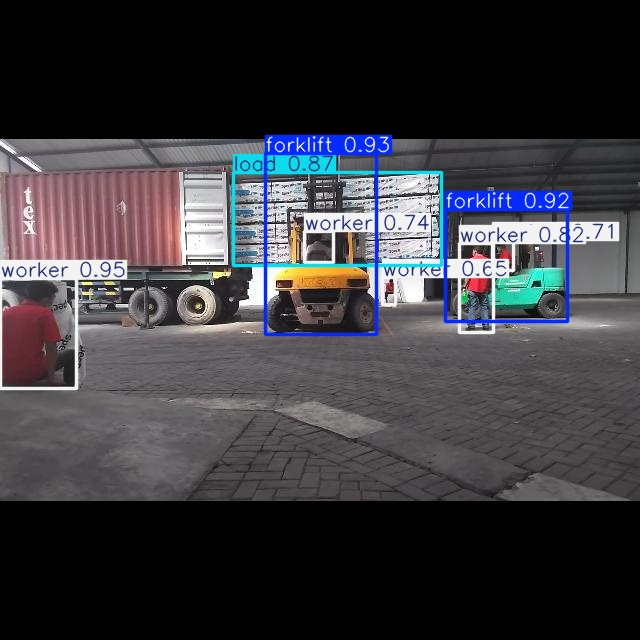

--------------------------------------------------
Displaying: runs/detect/predict/forklift-437-_png.rf.918d22cc507a27cfc58a2190c94a178a.jpg


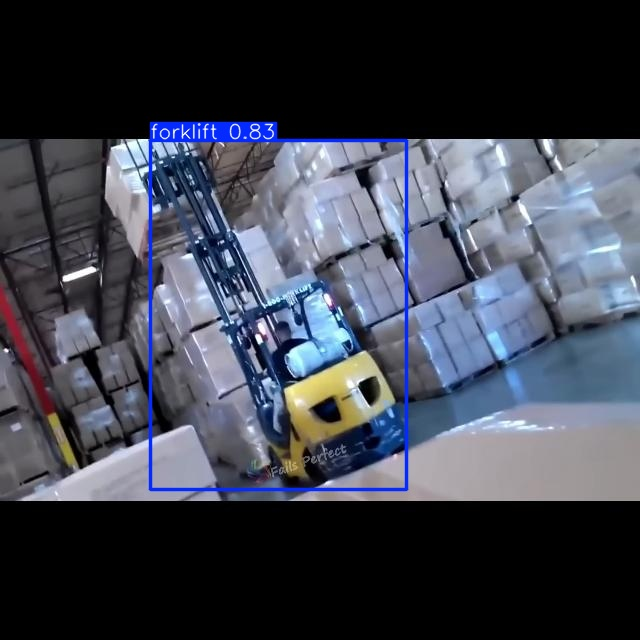

--------------------------------------------------
Displaying: runs/detect/predict/forklift-1721-_png.rf.9f839053bb130edcced7fa7e08fb70e8.jpg


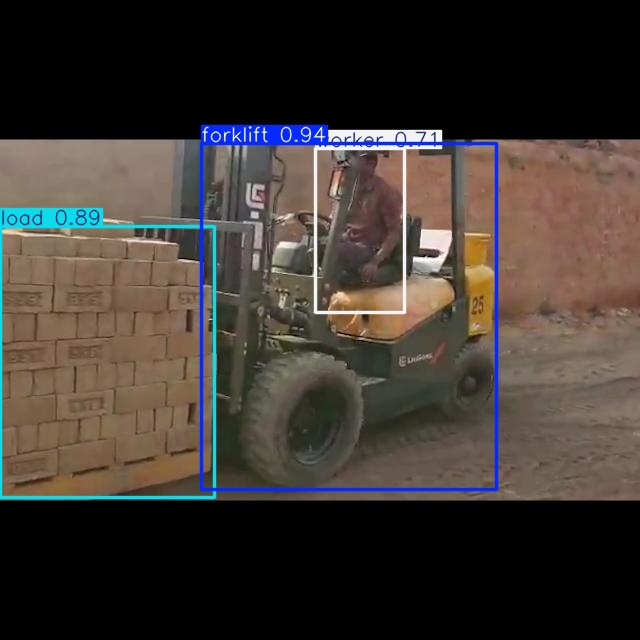

--------------------------------------------------
Displaying: runs/detect/predict/forklift-1863-_png.rf.16b13658de141a85bb34df273cc3486c.jpg


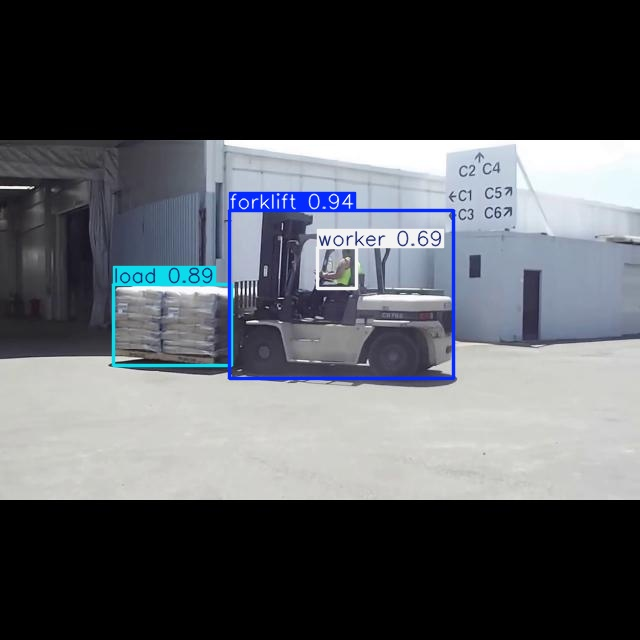

--------------------------------------------------
Displaying: runs/detect/predict/H-220927_E01_Y-50_005_-_MP4-32_jpg.rf.8e6c8231ab3ac3e3ff5bc6be813193f5.jpg


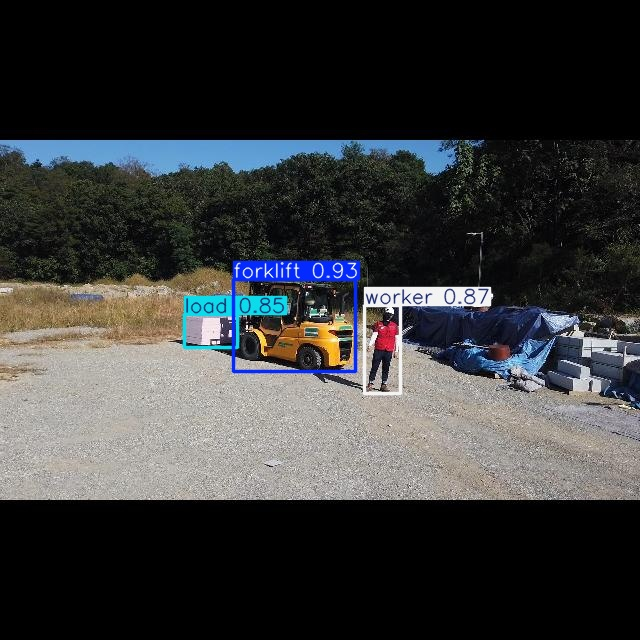

--------------------------------------------------
Displaying: runs/detect/predict/H-220927_E01_Y-50_005_-_MP4-13_jpg.rf.6739fd02809170cca2a91461776966fa.jpg


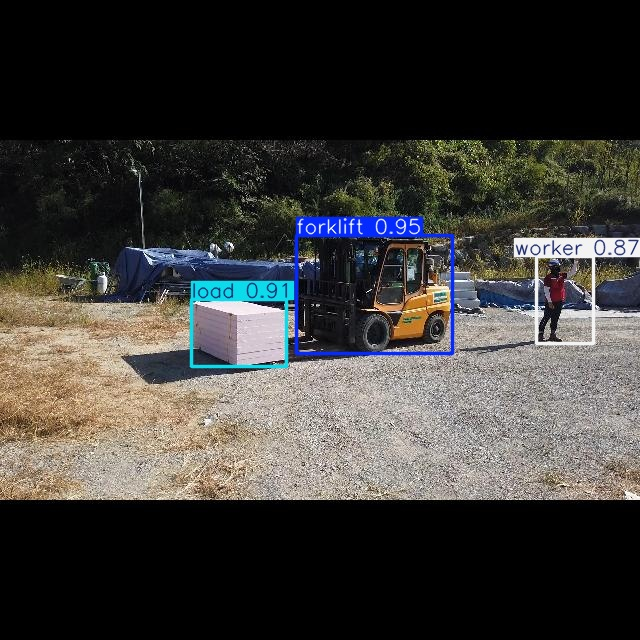

--------------------------------------------------
Displaying: runs/detect/predict/scene03251_png.rf.1cc5ff6f13be066bd7cff4863e47db2c.jpg


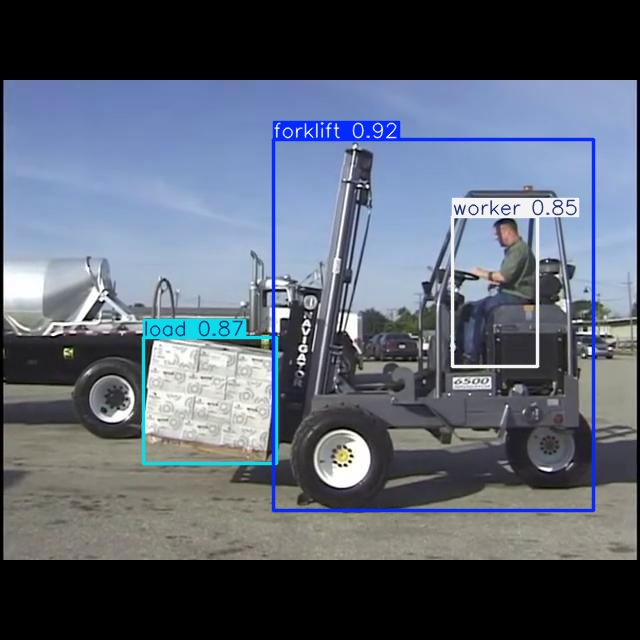

--------------------------------------------------
Displaying: runs/detect/predict/H-220927_E01_Y-49_008-_MP4-36_jpg.rf.6d202aab53c019e2d4dd7ce91563b587.jpg


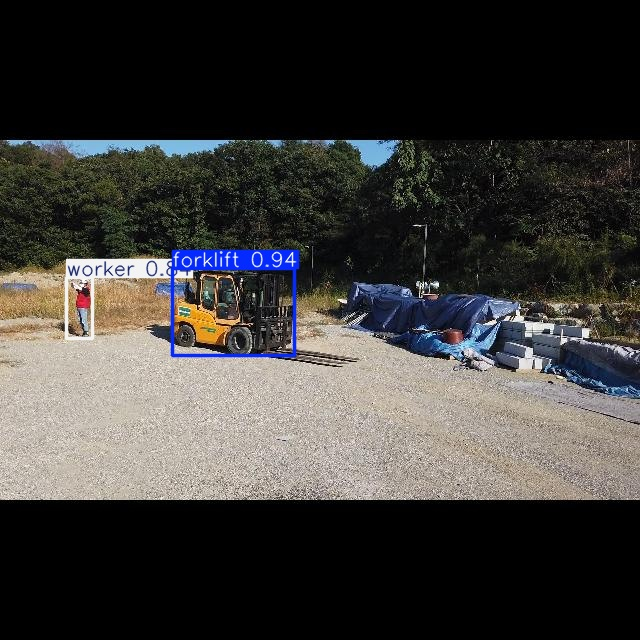

--------------------------------------------------
Displaying: runs/detect/predict/forklift-150-_png.rf.ea722ea0752c0944679287cee11385c1.jpg


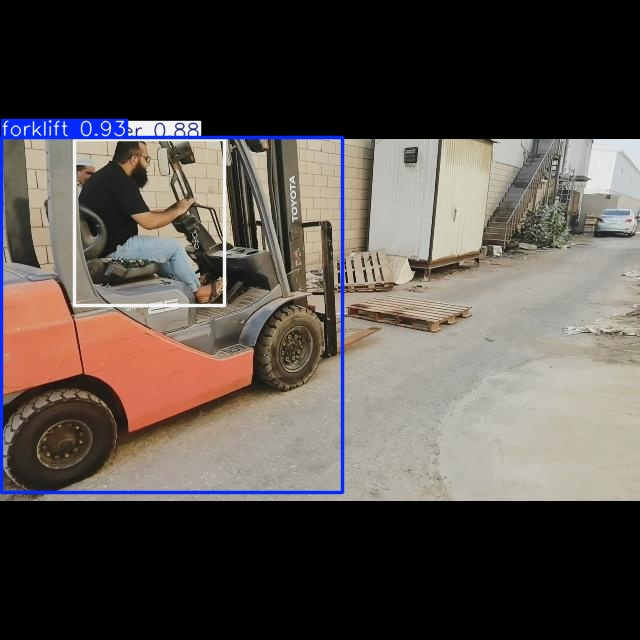

--------------------------------------------------
Displaying: runs/detect/predict/H-220927_E11_N-50_008_-__MP4-1_jpg.rf.afa8708c00f69f65a06c2de04cdb94d5.jpg


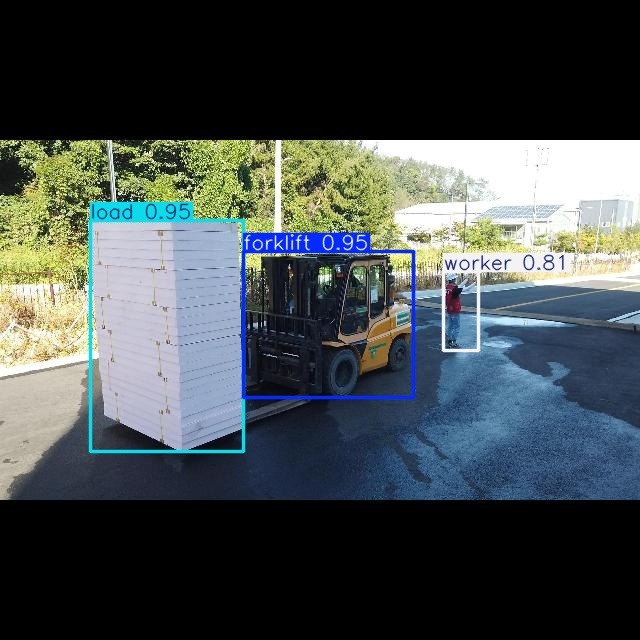

--------------------------------------------------


In [20]:
from ultralytics import YOLO
import glob
from IPython.display import Image, display

# 1. Load model and run prediction on test images
model = YOLO("/content/F2_project/runs/detect/f2_forklift_worker-2/weights/best.pt")
results = model.predict(source="/content/F2_project/Forklift-Dataset-3/test/images", conf=0.4, save=True)

# 2. Display first 10 annotated test images
image_paths = glob.glob("runs/detect/predict/*.jpg")
for img_path in image_paths[:10]:
    print(f"Displaying: {img_path}")
    display(Image(filename=img_path))
    print("-" * 50)

In [19]:
metrics = model.val(data="Forklift-Dataset-3/data.yaml", split="test")

print("\n================ FINAL TEST METRICS ================")
print(f"mAP50:     {metrics.box.map50:.3f}")
print(f"Precision: {metrics.box.mp:.3f}")
print(f"Recall:    {metrics.box.mr:.3f}")
print("====================================================")

Ultralytics 8.4.126 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1202.4±402.9 MB/s, size: 49.6 KB)
val: Scanning /content/F2_project/Forklift-Dataset-3/test/labels... 101 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 101/101 1.6Kit/s 0.1s
val: New cache created: /content/F2_project/Forklift-Dataset-3/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.0it/s 3.4s
                   all        101        332      0.961      0.941      0.958      0.781
              forklift        100        103      0.985       0.99      0.992      0.918
                  load         66         66      0.968      0.939      0.967      0.822
                worker         85        163       0.93      0.894      0.915      0.603
Speed: 7.0ms preprocess, 6.6ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /content/F2_project/runs/

Depth anything

In [21]:
!pip install transformers --quiet

from transformers import pipeline
from PIL import Image as PILImage
import glob

depth_estimator = pipeline(
    task="depth-estimation",
    model="depth-anything/Depth-Anything-V2-Small-hf"
)

# grab one test image from your dataset to try it on
test_images = glob.glob("/content/F2_project/Forklift-Dataset-3/test/images/*.jpg")
sample_image_path = test_images[0]

image = PILImage.open(sample_image_path)
result = depth_estimator(image)

depth_map = result["depth"]
depth_map.save("/content/F2_project/depth_sample_output.png")

print("Depth map saved. Source image:", sample_image_path)

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

Depth map saved. Source image: /content/F2_project/Forklift-Dataset-3/test/images/forklift-786-_png.rf.212c020125479afec9ece69b2905a85a.jpg


Original image:


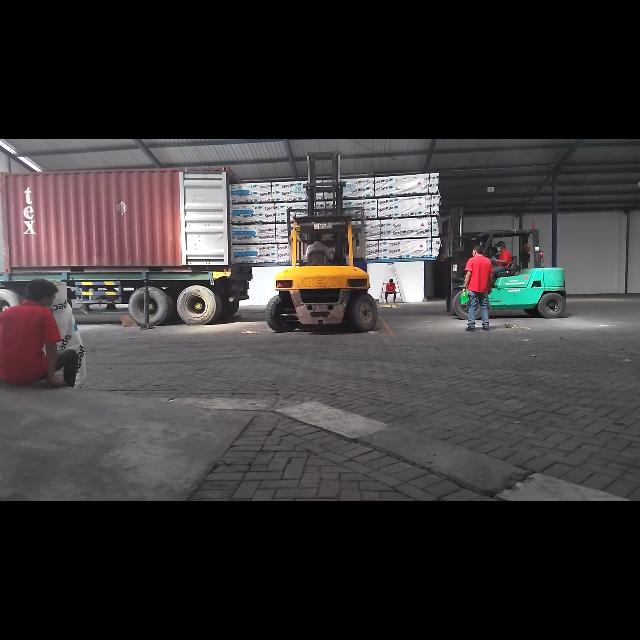

Depth map (brighter = closer):


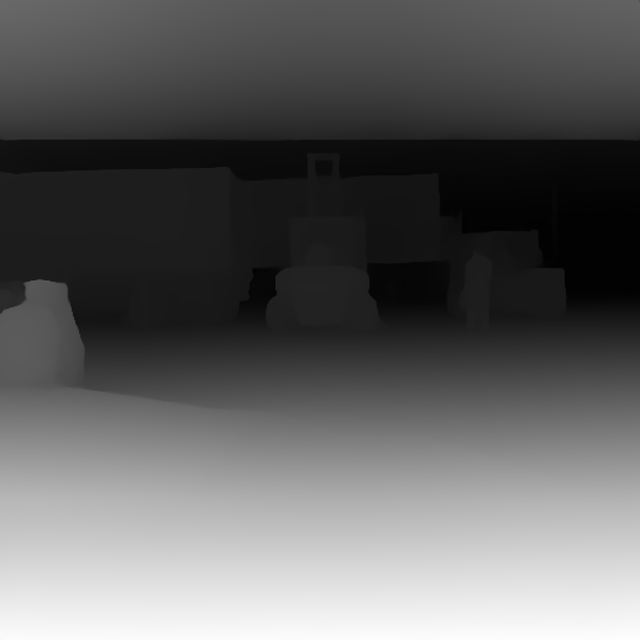

In [22]:
from IPython.display import display

print("Original image:")
display(image)

print("Depth map (brighter = closer):")
display(depth_map)

In [23]:
from google.colab import files

# Save the generated monocular depth map to the local Colab directory
depth_map.save("/content/depth_output.png")

# Download the depth map image directly to your computer
files.download("/content/depth_output.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
import numpy as np
from PIL import Image
from google.colab import files

# Resize the original test image to match the dimensions of the generated depth map
img_orig = image.resize(depth_map.size)

# Create a combined canvas to place both images side-by-side
combined_img = Image.new('RGB', (img_orig.width * 2, img_orig.height))
combined_img.paste(img_orig, (0, 0))                  # Place original image on the left
combined_img.paste(depth_map, (img_orig.width, 0))   # Place depth map on the right

# Save and download the side-by-side comparison for presentation slides
combined_img.save("/content/depth_comparison.png")
files.download("/content/depth_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>